# 11 — Margem de segurança por dia da semana

Testa se uma margem estimada separadamente por dia da semana reduz falta potencial sem gerar excesso desnecessário. Para cada corte temporal, usa o modelo escolhido no Notebook 10; estima margens somente com resíduos anteriores ao ano avaliado e compara, nas mesmas datas, quatro opções: margem global escolhida no Notebook 10, quantil residual global, quantil residual por dia sem regularização e quantil por dia com encolhimento para o global.

Para uma razão falta:sobra `r:1`, o quantil de calibração é `r/(r+1)`. A margem por dia é estimada do resíduo `consumo - previsão`; a versão regularizada combina quantil local e global com peso `n/(n+10)`, usando 10 observações como força fixa de regularização. Margens são limitadas a valores não negativos e a quantidade planejada usa arredondamento para cima, como no Notebook 06.

O corte 2023→2024 e 2023–2024→2025 separa calibração e avaliação. O cenário de margem global do Notebook 10 e as reservas são baselines pareados. Os pesos são hipóteses, e os erros potenciais não medem desperdício ou atendimento real.

In [1]:
from pathlib import Path
import os
import tempfile
import numpy as np
import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "mplconfig_novo_experimento"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
roots = [cwd, cwd.parent, cwd / "NOVO_EXPERIMENTO"]
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "consumo_cardapio_calendario"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
assert ROOT is not None, f"Não localizei NOVO_EXPERIMENTO a partir de {cwd}."
DATA_PATH = LINE_RESULTS / "09_margens_vs_reservas" / "previsoes_decisao_pareadas.csv"
SELECTION_PATH = LINE_RESULTS / "10_selecao_temporal_modelo_margem" / "resultado_selecao_temporal.csv"
OUT = LINE_RESULTS / "11_margem_por_dia_semana"
OUT.mkdir(parents=True, exist_ok=True)
data = pd.read_csv(DATA_PATH, encoding="utf-8-sig", parse_dates=["data"])
selection = pd.read_csv(SELECTION_PATH, encoding="utf-8-sig")
data["origem"] = pd.to_datetime(data["origem"], errors="raise")
assert (data["origem"] < data["data"]).all()
assert not data.duplicated(["metodo", "politica_margem", "data"]).any()
reserve_name = "Baseline_Reservas::total_reservas_observado"
forecast_rows = data[(data["metodo"] != reserve_name) & (data["politica_margem"] == "margem_fixa_0")].copy()
assert forecast_rows.groupby(["metodo", "data"])["previsao"].nunique().eq(1).all()
assert set(selection["ano_teste"]) == {2024, 2025} and len(selection) == 8
print(f"Previsões: {forecast_rows.metodo.nunique()} métodos; {forecast_rows.data.nunique()} datas; seleções temporais: {len(selection)}.")


Previsões: 65 métodos; 390 datas; seleções temporais: 8.


In [2]:
# Calibrar margens usando resíduos anteriores ao ano de teste.
cuts = {2024: [2023], 2025: [2023, 2024]}
weekday_names = {0: "segunda", 1: "terça", 2: "quarta", 3: "quinta", 4: "sexta", 5: "sábado", 6: "domingo"}
prior_strength = 10
margin_rows = []
decision_rows = []

def quantile_margin(values, q):
    values = pd.Series(values).dropna().to_numpy(dtype=float)
    return max(0.0, float(np.quantile(values, q))) if len(values) else 0.0

for selected in selection.itertuples(index=False):
    test_year = int(selected.ano_teste)
    train_years = cuts[test_year]
    ratio = int(selected.razao_falta_sobra)
    q = ratio / (ratio + 1)
    method = selected.metodo_selecionado
    global_policy = selected.politica_selecionada
    model_forecasts = forecast_rows[forecast_rows["metodo"] == method].copy()
    history = model_forecasts[model_forecasts["ano"].isin(train_years)].copy()
    future = model_forecasts[model_forecasts["ano"] == test_year].copy()
    assert history["data"].max() < future["data"].min()
    history["dia_semana"] = history["data"].dt.dayofweek
    future["dia_semana"] = future["data"].dt.dayofweek
    history["residuo_consumo_menos_previsao"] = history["consumo_real"] - history["previsao"]
    global_margin = quantile_margin(history["residuo_consumo_menos_previsao"], q)
    day_margins = {}
    for dow, day_name in weekday_names.items():
        local = history.loc[history["dia_semana"] == dow, "residuo_consumo_menos_previsao"].dropna()
        n = int(len(local))
        raw_local_q = float(np.quantile(local, q)) if n else global_margin
        weight = n / (n + prior_strength) if n else 0.0
        shrunk_margin = max(0.0, weight * raw_local_q + (1 - weight) * global_margin)
        day_margins[dow] = {"raw": max(0.0, raw_local_q), "shrunk": shrunk_margin, "n": n, "weight": weight}
        margin_rows.append({
            "ano_teste": test_year, "anos_calibracao": "+".join(map(str, train_years)),
            "razao_falta_sobra": ratio, "quantil_usado": q, "metodo": method,
            "dia_semana": day_name, "n_residuos": n,
            "quantil_residuo_global": global_margin,
            "quantil_residuo_dia_sem_regularizacao": raw_local_q,
            "peso_estimativa_local": weight,
            "margem_dia_regularizada": shrunk_margin,
        })

    # Baseline global selecionado no Notebook 10: modelo e regra escolhidos só no passado.
    global_fixed = data[(data["metodo"] == method) & (data["politica_margem"] == global_policy) & (data["ano"] == test_year)].copy()
    assert set(global_fixed["data"]) == set(future["data"])
    assert np.allclose(global_fixed["previsao"].to_numpy(), future["previsao"].to_numpy())
    reserve_future = data[(data["metodo"] == reserve_name) & (data["ano"] == test_year)].copy()
    assert set(reserve_future["data"]) == set(future["data"])

    future["previsao_nao_negativa"] = future["previsao"].clip(lower=0)
    future["margem_global_quantile"] = global_margin
    future["margem_dia_sem_regularizacao"] = future["dia_semana"].map({d: x["raw"] for d, x in day_margins.items()})
    future["margem_dia_regularizada"] = future["dia_semana"].map({d: x["shrunk"] for d, x in day_margins.items()})

    strategies = {
        "global_escolhida_notebook10": (global_fixed, "quantidade_planejada", "margem_refeicoes"),
    }
    for policy_name, margin_col in [
        ("quantil_global_residuos", "margem_global_quantile"),
        ("quantil_dia_sem_regularizacao", "margem_dia_sem_regularizacao"),
        ("quantil_dia_regularizada", "margem_dia_regularizada"),
    ]:
        plan = future.copy()
        plan["quantidade_planejada"] = np.ceil(plan["previsao_nao_negativa"] + plan[margin_col]).astype(int)
        plan["margem_refeicoes"] = plan[margin_col]
        strategies[policy_name] = (plan, "quantidade_planejada", "margem_refeicoes")
    strategies["reservas"] = (reserve_future, "quantidade_planejada", "margem_refeicoes")

    for policy_name, (frame, plan_col, margin_col) in strategies.items():
        result = frame[["data", "ano", "consumo_real", "previsao", plan_col, margin_col]].copy()
        result = result.rename(columns={plan_col: "quantidade_planejada", margin_col: "margem_aplicada"})
        result["excesso_potencial"] = (result["quantidade_planejada"] - result["consumo_real"]).clip(lower=0)
        result["falta_potencial"] = (result["consumo_real"] - result["quantidade_planejada"]).clip(lower=0)
        result["erro_abs_plano"] = (result["quantidade_planejada"] - result["consumo_real"]).abs()
        result["cobriu_dia"] = result["quantidade_planejada"] >= result["consumo_real"]
        result["ano_teste"] = test_year
        result["anos_calibracao"] = "+".join(map(str, train_years))
        result["razao_falta_sobra"] = ratio
        result["metodo_selecionado"] = method
        result["politica_global_selecionada"] = global_policy
        result["politica_avaliada"] = policy_name
        decision_rows.append(result)

margins = pd.DataFrame(margin_rows)
decisions = pd.concat(decision_rows, ignore_index=True)
margins.to_csv(OUT / "margens_calibradas_por_dia.csv", index=False, encoding="utf-8-sig")
decisions.to_csv(OUT / "decisoes_pareadas_por_dia.csv", index=False, encoding="utf-8-sig")
print(f"Margens calibradas: {len(margins)} combinações corte × razão × dia; planos pareados: {len(decisions):,}.")


Margens calibradas: 56 combinações corte × razão × dia; planos pareados: 5,540.


In [3]:
# Resumir métricas e comparar diretamente margem por dia com margem global.
summary_rows = []
for keys, group in decisions.groupby(["ano_teste", "anos_calibracao", "razao_falta_sobra", "metodo_selecionado", "politica_global_selecionada", "politica_avaliada"], sort=False):
    test_year, train_years, ratio, method, global_policy, strategy = keys
    target_total = group["consumo_real"].sum()
    summary_rows.append({
        "ano_teste": test_year, "anos_calibracao": train_years, "razao_falta_sobra": ratio,
        "metodo_selecionado": method, "politica_global_selecionada": global_policy,
        "politica_avaliada": strategy, "n_datas": group["data"].nunique(),
        "MAE_plano": group["erro_abs_plano"].mean(),
        "WAPE_plano_pct": group["erro_abs_plano"].sum() / target_total * 100,
        "excesso_medio_dia": group["excesso_potencial"].mean(),
        "falta_media_dia": group["falta_potencial"].mean(),
        "dias_com_cobertura_pct": group["cobriu_dia"].mean() * 100,
        "margem_media": group["margem_aplicada"].mean(),
        "perda_ponderada_media_dia": (group["excesso_potencial"] + int(ratio) * group["falta_potencial"]).mean(),
    })
summary = pd.DataFrame(summary_rows)
global_ref = summary[summary["politica_avaliada"] == "global_escolhida_notebook10"][
    ["ano_teste", "razao_falta_sobra", "perda_ponderada_media_dia"]
].rename(columns={"perda_ponderada_media_dia": "perda_global_selecionada"})
summary = summary.merge(global_ref, on=["ano_teste", "razao_falta_sobra"], validate="many_to_one")
summary["reducao_perda_vs_global_pct"] = (1 - summary["perda_ponderada_media_dia"] / summary["perda_global_selecionada"]) * 100
reserve_ref = summary[summary["politica_avaliada"] == "reservas"][
    ["ano_teste", "razao_falta_sobra", "perda_ponderada_media_dia"]
].rename(columns={"perda_ponderada_media_dia": "perda_reservas"})
summary = summary.merge(reserve_ref, on=["ano_teste", "razao_falta_sobra"], validate="many_to_one")
summary["reducao_perda_vs_reservas_pct"] = (1 - summary["perda_ponderada_media_dia"] / summary["perda_reservas"]) * 100
summary.to_csv(OUT / "metricas_margens_por_dia.csv", index=False, encoding="utf-8-sig")
display(summary[[
    "ano_teste", "razao_falta_sobra", "politica_avaliada", "MAE_plano", "WAPE_plano_pct",
    "margem_media", "excesso_medio_dia", "falta_media_dia", "perda_ponderada_media_dia",
    "reducao_perda_vs_global_pct", "reducao_perda_vs_reservas_pct",
]].round(2))

pivot = summary.pivot_table(index=["ano_teste", "razao_falta_sobra"], columns="politica_avaliada", values="perda_ponderada_media_dia")
assert set(pivot.columns) == {"global_escolhida_notebook10", "quantil_global_residuos", "quantil_dia_sem_regularizacao", "quantil_dia_regularizada", "reservas"}


,ano_teste,razao_falta_sobra,politica_avaliada,MAE_plano,WAPE_plano_pct,margem_media,excesso_medio_dia,falta_media_dia,perda_ponderada_media_dia,reducao_perda_vs_global_pct,reducao_perda_vs_reservas_pct
0,2024,1,global_escolhida_notebook10,27.95,16.71,0.00,8.76,19.19,27.95,0.00,29.81
1,2024,1,quantil_global_residuos,27.67,16.54,2.31,9.80,17.88,27.67,1.00,30.51
2,2024,1,quantil_dia_sem_regularizacao,28.45,17.01,3.37,10.70,17.75,28.45,-1.79,28.55
3,2024,1,quantil_dia_regularizada,28.21,16.87,2.81,10.30,17.92,28.21,-0.94,29.15
4,2024,1,reservas,39.82,23.81,0.00,2.74,37.08,39.82,-42.46,0.00
5,2024,2,global_escolhida_notebook10,28.85,17.25,10.00,12.79,16.07,44.92,0.00,41.59
6,2024,2,quantil_global_residuos,28.84,17.24,11.52,13.49,15.34,44.18,1.64,42.55
7,2024,2,quantil_dia_sem_regularizacao,30.12,18.01,9.47,13.11,17.01,47.13,-4.93,38.71
8,2024,2,quantil_dia_regularizada,30.11,18.00,9.33,13.06,17.05,47.16,-4.98,38.68
9,2024,2,reservas,39.82,23.81,0.00,2.74,37.08,76.90,-71.20,0.00


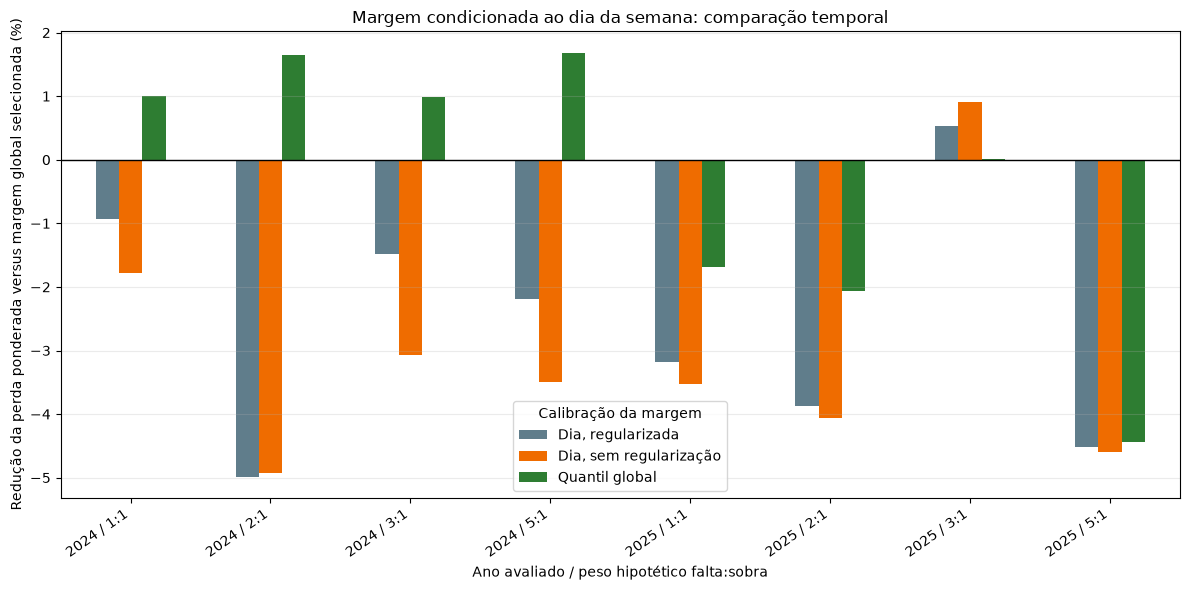

Gráfico salvo em F:\PRODUTO_MESTRADO\resultados\linhas\consumo_cardapio_calendario\11_margem_por_dia_semana\comparacao_margem_dia_semana.png; relatório em F:\PRODUTO_MESTRADO\resultados\linhas\consumo_cardapio_calendario\11_margem_por_dia_semana\RELATORIO_NOTEBOOK_11.md.


In [4]:
# Gráfico principal: redução da perda ponderada versus a margem global selecionada.
compare = summary[summary["politica_avaliada"].isin(["quantil_global_residuos", "quantil_dia_sem_regularizacao", "quantil_dia_regularizada"])].copy()
compare["corte"] = compare["ano_teste"].astype(str) + " / " + compare["razao_falta_sobra"].astype(str) + ":1"
chart_data = compare.pivot(index="corte", columns="politica_avaliada", values="reducao_perda_vs_global_pct")
chart_data = chart_data.rename(columns={
    "quantil_global_residuos": "Quantil global",
    "quantil_dia_sem_regularizacao": "Dia, sem regularização",
    "quantil_dia_regularizada": "Dia, regularizada",
})
ax = chart_data.plot(kind="bar", figsize=(12, 6), color=["#607D8B", "#EF6C00", "#2E7D32"])
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Redução da perda ponderada versus margem global selecionada (%)")
ax.set_xlabel("Ano avaliado / peso hipotético falta:sobra")
ax.set_title("Margem condicionada ao dia da semana: comparação temporal")
ax.grid(axis="y", alpha=.25)
ax.legend(title="Calibração da margem")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
chart_path = OUT / "comparacao_margem_dia_semana.png"
plt.savefig(chart_path, dpi=170, bbox_inches="tight")
plt.show()

pt = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")
main = summary[summary["politica_avaliada"].isin(["global_escolhida_notebook10", "quantil_global_residuos", "quantil_dia_regularizada", "reservas"])].copy()
lines = [
    "# Relatório — margem de segurança por dia da semana",
    "",
    "A margem por dia foi calibrada apenas com resíduos anteriores ao ano de teste. O modelo utilizado em cada corte é o selecionado pelo Notebook 10; previsões do ano de teste são as mesmas previsões walk-forward já avaliadas. A regularização usa força 10 para aproximar estimativas diárias da margem global quando há poucas observações.",
    "",
    "| Ano teste | Peso | Política | Margem média | MAE plano | WAPE | Excesso/dia | Falta/dia | Perda ponderada/dia | Δ perda vs global selecionada |",
    "|---:|---:|---|---:|---:|---:|---:|---:|---:|---:|",
]
for r in main.itertuples(index=False):
    lines.append(
        f"| {r.ano_teste} | {r.razao_falta_sobra}:1 | {r.politica_avaliada} | {pt(r.margem_media)} | {pt(r.MAE_plano)} | {pt(r.WAPE_plano_pct)}% | {pt(r.excesso_medio_dia)} | {pt(r.falta_media_dia)} | {pt(r.perda_ponderada_media_dia)} | {pt(r.reducao_perda_vs_global_pct, 1)}% |"
    )
lines += [
    "",
    "## Interpretação e limites",
    "",
    "A comparação principal é a política `quantil_dia_regularizada` contra `global_escolhida_notebook10` nas mesmas datas. Valor positivo em Δ significa perda ponderada retrospectiva menor que a margem global escolhida; valor negativo significa piora. O quantil global e o quantil diário sem regularização ajudam a entender se eventual diferença vem da condição por dia ou da calibração do quantil.",
    "",
    f"A margem por dia sem regularização melhorou em {(summary.loc[summary.politica_avaliada.eq('quantil_dia_sem_regularizacao'), 'reducao_perda_vs_global_pct'] > 0).sum()} de {len(summary.loc[summary.politica_avaliada.eq('quantil_dia_sem_regularizacao')])} cortes. A regularizada melhorou em {(summary.loc[summary.politica_avaliada.eq('quantil_dia_regularizada'), 'reducao_perda_vs_global_pct'] > 0).sum()} de {len(summary.loc[summary.politica_avaliada.eq('quantil_dia_regularizada')])}. Esses resultados não demonstram vantagem estável da condição por dia; cada ganho deve ser confirmado em nova janela.",
    "",
    "São apenas dois anos de teste e quatro cenários de penalidade hipotéticos. A regra newsvendor `r/(r+1)` só é interpretável como ótima se os custos por falta e excesso forem constantes e corretamente representados por esses pesos, algo não medido aqui. Uma boa perda hipotética não comprova menos desperdício nem melhor atendimento.",
    "",
    "As amostras por dia da semana são pequenas, sobretudo na calibração de 2023. A regularização reduz a instabilidade, mas o parâmetro 10 é uma escolha fixa e deve ser tratado como parte do experimento. A validação final ainda depende de produção, sobras e refeições não atendidas observadas.",
    "",
    "Consulte `metricas_margens_por_dia.csv`, `margens_calibradas_por_dia.csv` e `decisoes_pareadas_por_dia.csv`.",
]
(OUT / "RELATORIO_NOTEBOOK_11.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(f"Gráfico salvo em {chart_path}; relatório em {OUT / 'RELATORIO_NOTEBOOK_11.md'}.")


## Regras contra vazamento e limites

- O método e a margem global de referência vêm da seleção temporal do Notebook 10, baseada apenas em anos anteriores.
- Quantis globais e por dia da semana são calculados apenas com resíduos de treino; a data avaliada nunca contribui à sua própria margem.
- Margens usam previsão contínua não negativa e a mesma regra de arredondamento para cima do Notebook 06.
- A margem por dia é regularizada em direção à global com força fixa de 10 observações; também é reportada a versão sem regularização para diagnóstico.
- Os pesos são hipotéticos e os desvios plano-consumo não medem produção, desperdício, cobertura de refeições reais ou faltas de atendimento.